# Kasen (2010) SN Ia Companion Interaction Model

In the single-degenerate scenario a Type Ia supernova (SN Ia) explodes in a binary system with a
non-degenerate companion star. The supernova ejecta collide with the companion, which carves a hole in
the otherwise optically thick ejecta. Until the ejecta wrap around the companion and close the hole,
radiation escapes through it and produces excess emission in the first days after explosion. How much
of this emission we see depends on the companion and on the viewing angle.

`KasenIaCompanionModel` simulates this early emission using the spectral time series computed by
[Kasen (2010)](https://doi.org/10.1088/0004-637X/708/2/1025). The spectra include both the
interaction and the underlying supernova emission. The companion fills its Roche lobe, so a single
number, the binary separation $a$, describes both its mass and its distance. Three companions are available:

| `companion` | Companion star | Separation |
|---|---|---|
| `"a5e11"` | $2\,M_\odot$ main sequence | $5\times10^{11}$ cm |
| `"a2e12"` | $6\,M_\odot$ main sequence | $2\times10^{12}$ cm |
| `"a2e13"` | $1\,M_\odot$ red giant | $2\times10^{13}$ cm |

The model has one model-specific parameter, `viewing_angle` (in degrees). At $0^\circ$ the companion
lies between the observer and the exploding white dwarf, so we look straight into the hole. At $180^\circ$
the white dwarf lies between the observer and the companion. The spectra are given on a grid of:

* 100 epochs, from 0.05 to 9.95 days after explosion (the model's `t0` is the time of explosion),
* 149 wavelengths, from 51 to 14851 Å,
* 40 viewing angles, from 12.84° to 167.16°, equally spaced in $\cos\theta$.

The model interpolates linearly in time, wavelength, and viewing angle, and it is zero outside the grid
in any of the three dimensions.

The spectra come from the [prestocolor](https://github.com/fedhere/prestocolor) repository
([Bianco et al. 2019](https://doi.org/10.1088/1538-3873/ab121a)) and are downloaded on first use.

In [1]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from astropy.cosmology import Planck18

from lightcurvelynx.astro_utils.mag_flux import flux2mag
from lightcurvelynx.astro_utils.passbands import PassbandGroup
from lightcurvelynx.graph_state import GraphState
from lightcurvelynx.math_nodes.np_random import NumpyRandomFunc
from lightcurvelynx.models.kasen_ia_companion import KASEN_COMPANIONS, KasenIaCompanionModel
from lightcurvelynx.models.multi_object_model import RandomMultiObjectModel
from lightcurvelynx.obstable.lsst_obstable import LSSTObsTable
from lightcurvelynx.simulate import compute_single_noise_free_lightcurve, simulate_lightcurves
from lightcurvelynx.survey_info import SurveyInfo
from lightcurvelynx.utils.plotting import plot_lightcurves

# A fixed color for each companion and labels for the plots.
COMPANION_COLORS = {"a5e11": "#2a78d6", "a2e12": "#eb6834", "a2e13": "#1baf7a"}
COMPANION_LABELS = {
    "a5e11": r"2 $M_\odot$ MS",
    "a2e12": r"6 $M_\odot$ MS",
    "a2e13": r"1 $M_\odot$ RG",
}
# A single-hue ramp for the viewing angle (darker = closer to the companion direction).
ANGLE_COLORS = ["#0d366b", "#256abf", "#5598e7", "#86b6ef"]

for name, description in KASEN_COMPANIONS.items():
    print(f"{name}: {description}")

a5e11: 2 M_sun main sequence star (separation a = 5e11 cm)
a2e12: 6 M_sun main sequence star (separation a = 2e12 cm)
a2e13: 1 M_sun red giant (separation a = 2e13 cm)


## Creating the models

We create one model per companion. To look at the intrinsic properties of the model we place the
supernovae at 10 pc (so that AB magnitudes are absolute magnitudes) and set the explosion time `t0` to 0.

In [2]:
models = {
    companion: KasenIaCompanionModel(companion, viewing_angle=90.0, t0=0.0, distance=10.0)
    for companion in KASEN_COMPANIONS
}

model = models["a2e13"]
print(f"Times: {len(model.times)} epochs, {model.times[0]} to {model.times[-1]} days")
print(f"Wavelengths: {len(model.wavelengths)} values, {model.wavelengths[0]} to {model.wavelengths[-1]} Å")
print(f"Viewing angles: {len(model.angles)} values, {model.angles[0]} to {model.angles[-1]} degrees")

Times: 100 epochs, 0.05 to 9.95 days
Wavelengths: 149 values, 51.0 to 14851.0 Å
Viewing angles: 40 values, 12.8386 to 167.1616 degrees


## Spectra

`compute_luminosity` returns the specific luminosity $L_\lambda$ (in erg/s/Å) for any times since
explosion, wavelengths, and viewing angle. The spectra come from a Monte Carlo radiative transfer
calculation, so they are noisy at the 100 Å resolution of the grid. The noise averages out when
the spectra are integrated over a passband.

Below are the spectra at a few epochs for the viewing angle closest to the companion direction (12.84°)
and the one farthest from it (167.16°). The interaction signal, which is strongest for the red giant,
shows up as blue emission at early times for small viewing angles.

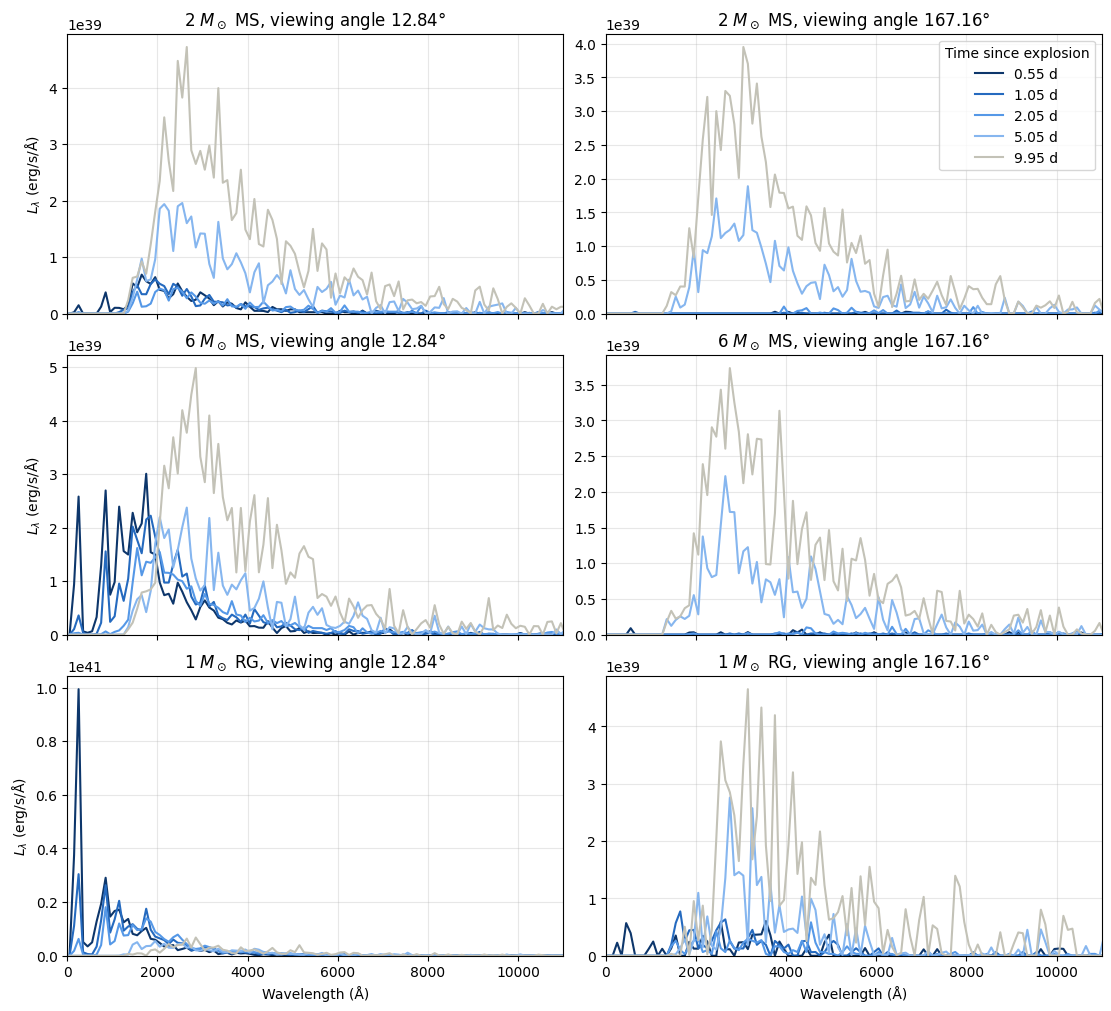

In [3]:
plot_epochs = [0.55, 1.05, 2.05, 5.05, 9.95]
plot_angles = [12.8386, 167.1616]
waves = model.wavelengths

fig, axes = plt.subplots(3, 2, figsize=(11, 10), sharex=True, layout="constrained")
for row, companion in enumerate(KASEN_COMPANIONS):
    for col, angle in enumerate(plot_angles):
        ax = axes[row, col]
        lum = models[companion].compute_luminosity(plot_epochs, waves, angle)
        for epoch, spectrum, color in zip(plot_epochs, lum, ANGLE_COLORS + ["#c3c2b7"], strict=True):
            ax.plot(waves, spectrum, lw=1.5, color=color, label=f"{epoch:.2f} d")
        ax.set_title(f"{COMPANION_LABELS[companion]}, viewing angle {angle:.2f}°")
        ax.set_xlim(0, 11000)
        ax.set_ylim(0, None)
        ax.grid(alpha=0.3)
    axes[row, 0].set_ylabel(r"$L_\lambda$ (erg/s/Å)")
axes[-1, 0].set_xlabel("Wavelength (Å)")
axes[-1, 1].set_xlabel("Wavelength (Å)")
axes[0, 1].legend(title="Time since explosion")
plt.show()

## The full time-wavelength surface

For a fixed viewing angle the model is a surface over time and wavelength. Here we show it for the red
giant companion at the two extreme viewing angles in the optical range, where the interaction shows up
as an early blue excess at the small viewing angle. Both panels share the same vertical scale.

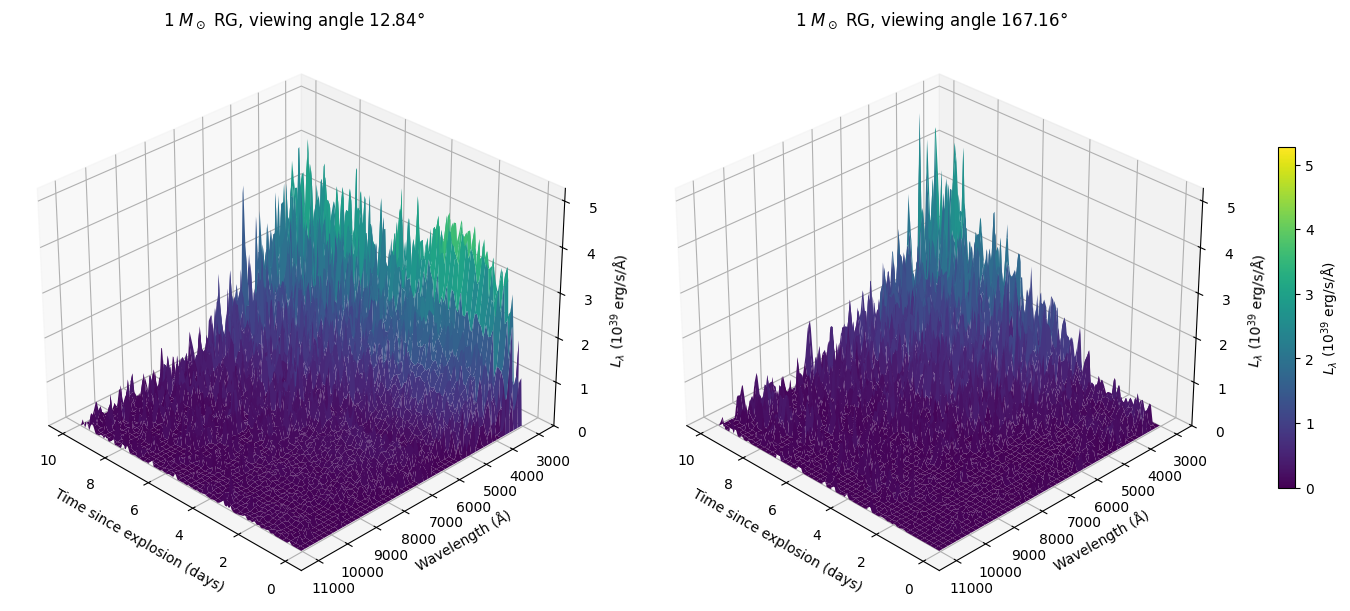

In [4]:
red_giant = models["a2e13"]
dense_times = np.linspace(red_giant.minphase(), red_giant.maxphase(), 300)
dense_waves = np.linspace(3000.0, 11000.0, 300)
time_mesh, wave_mesh = np.meshgrid(dense_times, dense_waves, indexing="ij")

surfaces = [red_giant.compute_luminosity(dense_times, dense_waves, angle) / 1e39 for angle in plot_angles]
z_max = max(surface.max() for surface in surfaces)

fig, axes = plt.subplots(1, 2, figsize=(14, 6), subplot_kw={"projection": "3d"}, layout="constrained")
for ax, angle, surface in zip(axes, plot_angles, surfaces, strict=True):
    surf = ax.plot_surface(
        time_mesh, wave_mesh, surface, cmap="viridis", vmin=0.0, vmax=z_max, edgecolor="none"
    )
    ax.set_zlim(0.0, z_max)
    ax.view_init(elev=30, azim=135)
    ax.set_title(f"{COMPANION_LABELS['a2e13']}, viewing angle {angle:.2f}°")
    ax.set_xlabel("Time since explosion (days)")
    ax.set_ylabel("Wavelength (Å)")
    ax.set_zlabel(r"$L_\lambda$ ($10^{39}$ erg/s/Å)")
fig.colorbar(surf, ax=axes, shrink=0.6, label=r"$L_\lambda$ ($10^{39}$ erg/s/Å)")
plt.show()

## Bolometric light curves

Integrating the spectra over wavelength gives the (pseudo-)bolometric luminosity between 51 and 14851 Å.
The interaction makes the early emission orders of magnitude brighter for small viewing angles, especially
for the red giant. By ~10 days the supernova itself dominates and all the light curves converge.

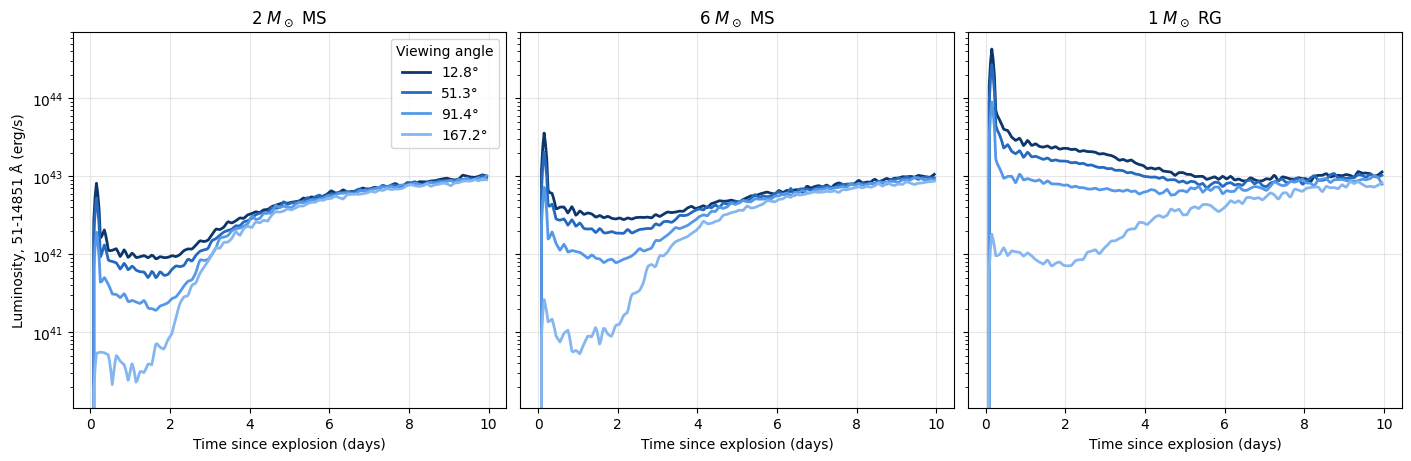

In [5]:
bol_angles = [12.8386, 51.3179, 91.4326, 167.1616]

fig, axes = plt.subplots(1, 3, figsize=(14, 4.5), sharey=True, layout="constrained")
for ax, companion in zip(axes, KASEN_COMPANIONS, strict=True):
    for angle, color in zip(bol_angles, ANGLE_COLORS, strict=True):
        lum = models[companion].compute_luminosity(dense_times, waves, angle)
        l_bol = np.trapezoid(lum, waves, axis=1)
        ax.plot(dense_times, l_bol, lw=2, color=color, label=f"{angle:.1f}°")
    ax.set_yscale("log")
    ax.set_title(COMPANION_LABELS[companion])
    ax.set_xlabel("Time since explosion (days)")
    ax.grid(alpha=0.3)
axes[0].set_ylabel("Luminosity, 51-14851 Å (erg/s)")
axes[0].legend(title="Viewing angle")
plt.show()

## Light curves in LSST passbands

The model is a regular `SEDModel`, so we can evaluate it in any passband. Since the models are at
10 pc, the AB magnitudes below are absolute magnitudes. Note that the times we give to the model are
in MJD; here `t0=0`, so they are equal to the times since explosion.

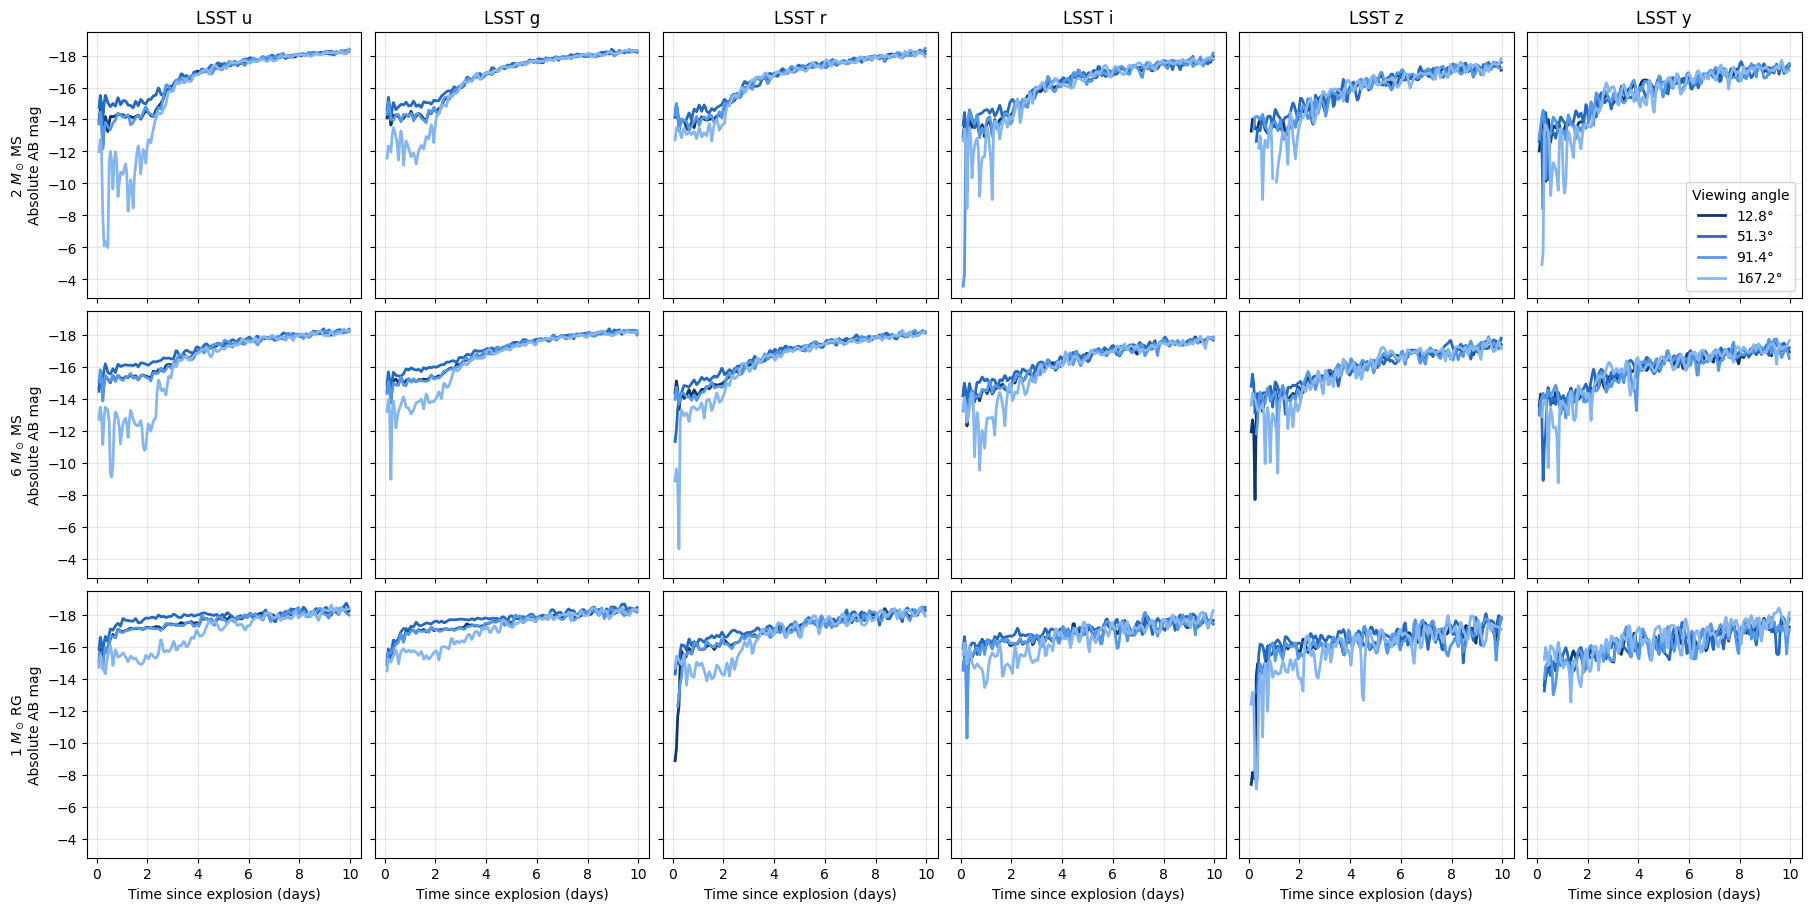

In [6]:
# Use a (possibly older) cached version of the passbands to avoid downloading them.
table_dir = "../../../tests/lightcurvelynx/data/passbands"
passband_group = PassbandGroup.from_preset(preset="LSST", table_dir=table_dir)

lc_times = np.linspace(0.05, 9.95, 200)
lc_filters = ["u", "g", "r", "i", "z", "y"]

fig, axes = plt.subplots(
    len(KASEN_COMPANIONS), len(lc_filters), figsize=(18, 9), sharex=True, sharey=True, layout="constrained"
)
for row, (companion, model) in enumerate(models.items()):
    for angle, color in zip(bol_angles, ANGLE_COLORS, strict=True):
        state = model.sample_parameters(given_args={model.node_string: {"viewing_angle": angle}})
        for col, filter_name in enumerate(lc_filters):
            fluxes = model.evaluate_bandfluxes(
                passband_group, lc_times, np.full(len(lc_times), filter_name), state
            )
            # Some bins have no Monte Carlo photon packets, so the flux can be zero there.
            with np.errstate(divide="ignore"):
                mags = flux2mag(fluxes)
            axes[row, col].plot(lc_times, mags, lw=2, color=color, label=f"{angle:.1f}°")
    axes[row, 0].set_ylabel(f"{COMPANION_LABELS[companion]}\nAbsolute AB mag")
for col, filter_name in enumerate(lc_filters):
    axes[0, col].set_title(f"LSST {filter_name}")
    axes[-1, col].set_xlabel("Time since explosion (days)")
for ax in axes.flat:
    ax.grid(alpha=0.3)
axes[0, 0].invert_yaxis()
axes[0, -1].legend(title="Viewing angle")
plt.show()

## Sampling parameters

If `viewing_angle` is not given, the model samples it isotropically (uniformly in $\cos\theta$) within
the range covered by the grid. As with any `SEDModel`, we can also sample the other parameters. Here we
sample the explosion time and the redshift, and compute the luminosity distance from the redshift
using a cosmology.

In [7]:
t0_min, t0_max = 61000.0, 61010.0
sampled_model = KasenIaCompanionModel(
    "a2e13",
    t0=NumpyRandomFunc("uniform", low=t0_min, high=t0_max),
    redshift=NumpyRandomFunc("uniform", low=0.01, high=0.05),
    cosmology=Planck18,
    ra=150.0,
    dec=-30.0,
    node_label="kasen",
)

state = sampled_model.sample_parameters(num_samples=1000)
pd.DataFrame({key: state["kasen"][key] for key in ["t0", "redshift", "distance", "viewing_angle"]}).head()

,t0,redshift,distance,viewing_angle
0,61007.419781,0.034512,1.569148e+08,39.239950
1,61001.856792,0.043285,1.980556e+08,136.045605
2,61005.318553,0.017501,7.857705e+07,90.118158
3,61004.792025,0.024484,1.105030e+08,43.760251
4,61009.556838,0.024467,1.104249e+08,51.798055


A `RandomMultiObjectModel` lets us simulate a population with a mix of companions. Each sample selects one
of the companion models at random (with the given weights) and the shared parameters (here the explosion
time and the redshift) are sampled by the wrapper model.

In [8]:
t0_sampler = NumpyRandomFunc("uniform", low=t0_min, high=t0_max)
redshift_sampler = NumpyRandomFunc("uniform", low=0.01, high=0.05)
population = RandomMultiObjectModel(
    [
        KasenIaCompanionModel(
            companion,
            t0=t0_sampler,
            redshift=redshift_sampler,
            cosmology=Planck18,
            ra=150.0,
            dec=-30.0,
            node_label=companion,
        )
        for companion in KASEN_COMPANIONS
    ],
    weights=[0.4, 0.4, 0.2],
    ra=150.0,
    dec=-30.0,
    node_label="population",
)

population_state = population.sample_parameters(num_samples=1000)
np.unique(population_state["population"]["selected_object"], return_counts=True)

(array(['a2e12', 'a2e13', 'a5e11'], dtype='<U5'), array([405, 211, 384]))

## Simulating survey light curves

The interaction signal lasts only a few days, so detecting it requires a high cadence. Here we simulate
a fake LSST-like survey that observes a single field six times per night, once in each of the u, g, r,
i, z, and y bands, for 25 nights. The noise parameters are similar to those of Rubin DP2. We only simulate observations during
the first 10 rest frame days after explosion, which is the time range covered by the model.

In [9]:
rng = np.random.default_rng(42)
filters = ["u", "g", "r", "i", "z", "y"]
num_nights = 25
obs_times = (61000.0 + np.arange(num_nights)[:, None] + 0.02 * np.arange(len(filters))).ravel()
num_obs = len(obs_times)
fake_data = {
    "expMidptMJD": obs_times,  # MJD
    "ra": np.full(num_obs, 150.0),  # Degrees
    "dec": np.full(num_obs, -30.0),  # Degrees
    "band": [filters[i % len(filters)] for i in range(num_obs)],
    "exptime": np.full(num_obs, 30.0),  # Seconds
    "pixelScale": np.full(num_obs, 0.2),  # Arcseconds per pixel
    "seeing": rng.uniform(low=0.84, high=0.88, size=num_obs),  # Arcseconds
    "skyBg": rng.uniform(low=1420.0, high=1430.0, size=num_obs),  # ADU
    "zeroPoint": rng.normal(loc=30.0, scale=0.5, size=num_obs),  # Magnitudes to produce 1 count (ADU)
}
obs_table = LSSTObsTable(pd.DataFrame(fake_data))
survey_info = SurveyInfo(obstable=obs_table, passbands=passband_group, survey_name="LSST")

lightcurves = simulate_lightcurves(
    sampled_model,
    4,
    survey_info,
    rest_time_window_offset=(sampled_model.minphase(), sampled_model.maxphase()),
    rng=rng,
)
params_col = lightcurves["params"].copy()
lightcurves = lightcurves.drop(columns=["params"])
lightcurves.head()

Simulating:   0%|          | 0/4 [00:00<?, ?obj/s]

Simulating: 100%|██████████| 4/4 [00:00<00:00, 513.55obj/s]

id     ra   dec  nobs            t0         z  \
0   0  150.0 -30.0    60  61001.451303  0.028342   
1   1  150.0 -30.0    60  61009.460245  0.041363   
2   2  150.0 -30.0    62  61003.013426  0.035456   
3   3  150.0 -30.0    63  61005.780172  0.032897   

                                          lightcurve  
0  [{mjd: 61002.0, filter: 'u', flux: 112423.9945...  
1  [{mjd: 61010.0, filter: 'u', flux: 49093.04706...  
2  [{mjd: 61003.08, filter: 'z', flux: 3375.55657...  
3  [{mjd: 61006.0, filter: 'u', flux: 20500.04763...

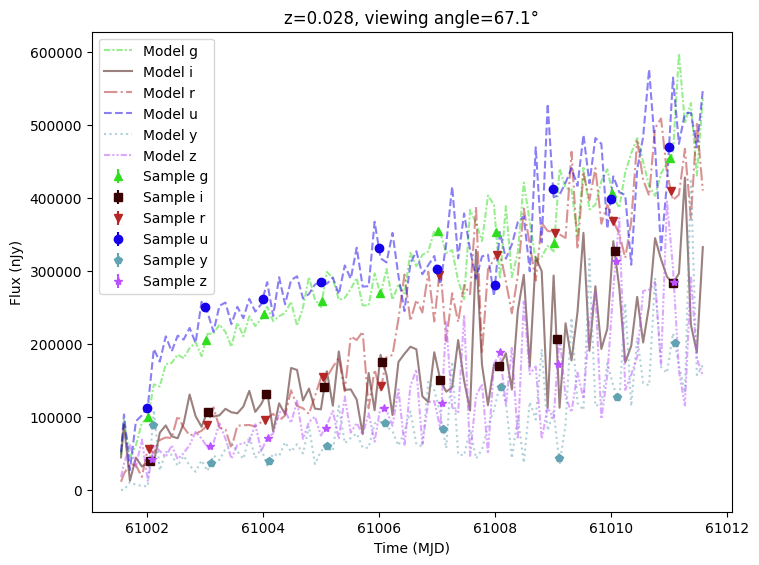

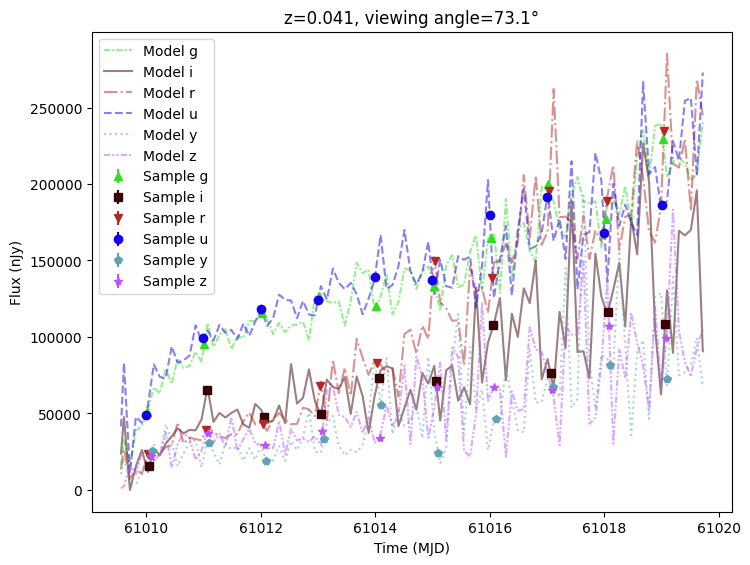

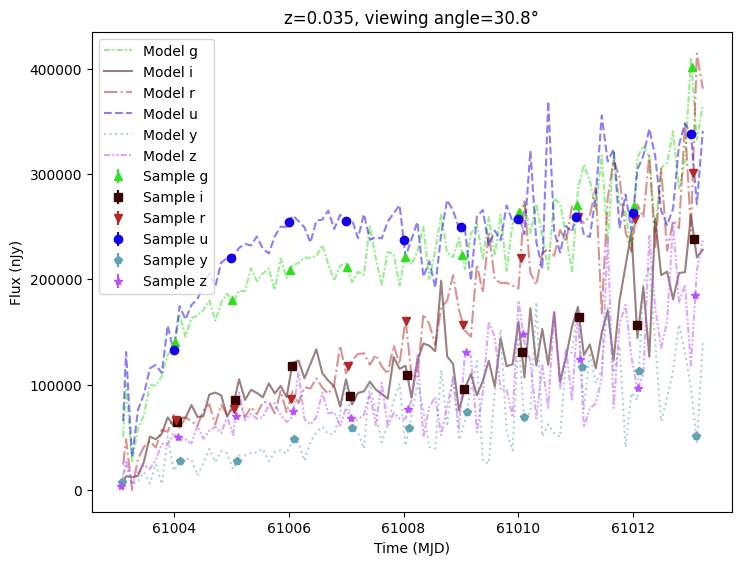

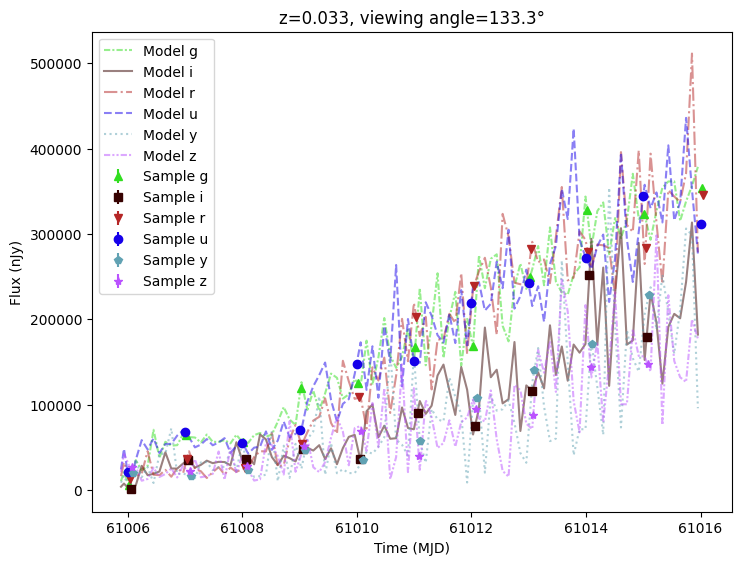

In [10]:
for idx in range(len(lightcurves)):
    lc = lightcurves.iloc[idx]["lightcurve"]
    params_dict = params_col.iloc[idx]
    noise_free_lcs = compute_single_noise_free_lightcurve(
        sampled_model,
        GraphState.from_dict(params_dict),
        passband_group,
        # Stay slightly inside the grid, since the conversion between the observer and the
        # rest frame can move the boundary times outside of it by a rounding error.
        rest_frame_phase_min=0.1,
        rest_frame_phase_max=9.9,
        rest_frame_phase_step=0.05,
    )
    plot_lightcurves(
        fluxes=np.asarray(lc["flux"], dtype=float),
        times=np.asarray(lc["mjd"], dtype=float),
        fluxerrs=np.asarray(lc["fluxerr"], dtype=float),
        filters=np.asarray(lc["filter"], dtype=str),
        underlying_model=noise_free_lcs,
        title=(
            f"z={params_dict['kasen.redshift']:.3f}, viewing angle={params_dict['kasen.viewing_angle']:.1f}°"
        ),
    )

## Citations

The model registers the Kasen (2010) paper and the data loader registers the Bianco et al. (2019)
paper and the prestocolor repository with `citation_compass`. Both are marked as used once a model is
created. See the [citations notebook](../citations.ipynb) for more details.

In [11]:
import citation_compass as cc

cc.print_used_citations()

lightcurvelynx.models.kasen_ia_companion.load_kasen_companion_grid:
* Data: Bianco F. B. et al., 2019, PASP, 131, 068002 - https://doi.org/10.1088/1538-3873/ab121a
* Repository: https://github.com/fedhere/prestocolor

lightcurvelynx.astro_utils.passbands.PassbandGroup._lsst_load_preset:
LSST Filters: https://github.com/lsst/throughputs

lightcurvelynx.models.kasen_ia_companion.KasenIaCompanionModel:
* Model: Kasen D., 2010, ApJ, 708, 1025 - https://doi.org/10.1088/0004-637X/708/2/1025

